## Making the random data set for regression

In [ ]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.datasets import make_regression

In [56]:
X,y = make_regression(n_features=1,n_samples=4,n_targets=1,noise=80,random_state=42)

In [71]:
X,y

(array([[ 0.64768854],
        [-0.1382643 ],
        [ 1.52302986],
        [ 0.49671415]]),
 array([-36.36510221,  78.68404196, -18.25147982,  30.07297006]))

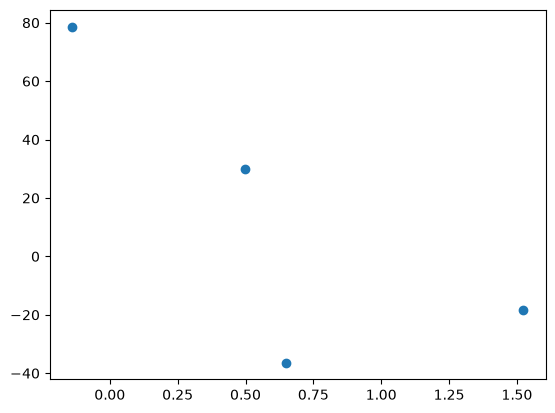

In [57]:
plt.scatter(X,y)

### Plotting the best fit line

<Axes: >

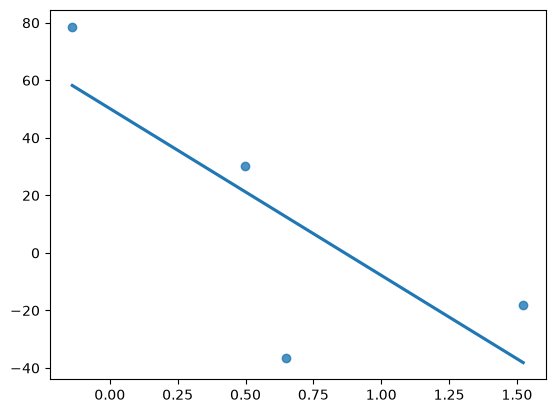

In [62]:
sns.regplot(x=X,y=y,ci=None)

## Calculating the slope using OLS 
I am calculating the slope because I will update the values of B only for now

In [140]:
from sklearn.linear_model import LinearRegression

In [141]:
lr = LinearRegression()

In [142]:
lr.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-57.99]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,50.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1.19]


In [143]:
lr.coef_
# this is the value of slope

array([-57.99225681])

In [144]:
lr.intercept_
#this is the value of intercept (B)

np.float64(50.20315110942306)

### Starting the iterations with B's starting value as 0 and m is constant (-57.99)

In [145]:
b = 0
y_pred = ((lr.coef_ * X) + b).reshape(4) # reshaping because y and y_pred should have same dimensions
y_pred

array([-37.56092003,   8.01825886, -88.32393856, -28.80557472])

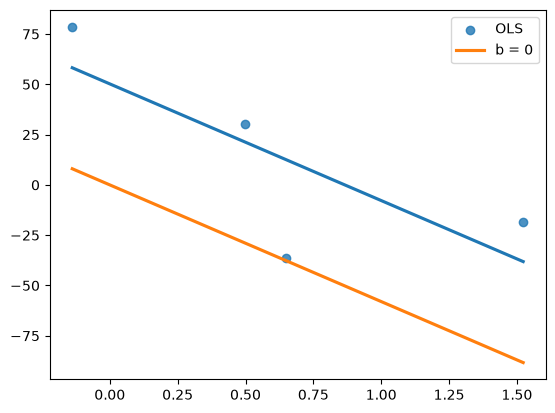

In [146]:
sns.regplot(x=X,y=y,ci=None,label='OLS')
sns.regplot(x=X,y=y_pred,ci=None,label='b = 0',scatter=False)
plt.legend()

### Calculating the value of B 
This formula is found by taking partial derivative of the loss function (Sum of Squared errors) with respect to B

In [147]:
loss_slope = -2*np.sum(y - lr.coef_*X.ravel() -b)
loss_slope

np.float64(-401.6252088753845)

In [148]:
# n(learning rate) = 0.1
n = 0.1
step_size = loss_slope*n
step_size

np.float64(-40.16252088753845)

In [149]:
b = b - step_size
b

np.float64(40.16252088753845)

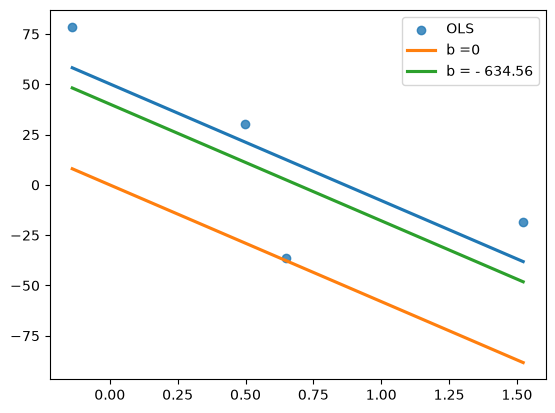

In [150]:
sns.regplot(x=X,y=y,ci=None,label='OLS')
sns.regplot(x=X,y=y_pred,ci=None,scatter=False,label = 'b =0')
sns.regplot(x=X,y=((lr.coef_ * X) + b).reshape(4),ci=None,label='b = 40.16252',scatter=False)
plt.legend()

In [151]:
loss_slope = -2*np.sum(y - lr.coef_*X.ravel() - b)
loss_slope

np.float64(-80.32504177507693)

In [152]:
step_size = n*loss_slope
step_size

np.float64(-8.032504177507693)

In [153]:
b = b - step_size
b

np.float64(48.19502506504614)

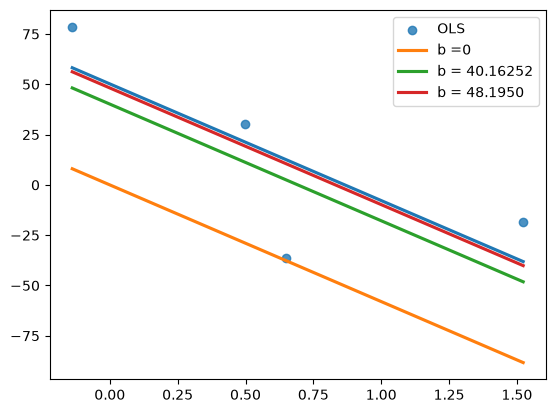

In [155]:
sns.regplot(x=X,y=y,ci=None,label='OLS')
sns.regplot(x=X,y=y_pred,ci=None,scatter=False,label = 'b =0')
sns.regplot(x=X,y=((lr.coef_ * X) + 40.16252).reshape(4),ci=None,label='b = 40.16252',scatter=False)
sns.regplot(x=X,y=((lr.coef_ * X) + b).reshape(4),ci=None,label='b = 48.1950',scatter=False)
plt.legend()
plt.show()
# our line is getting closer to the original line which we calculated using the OLS

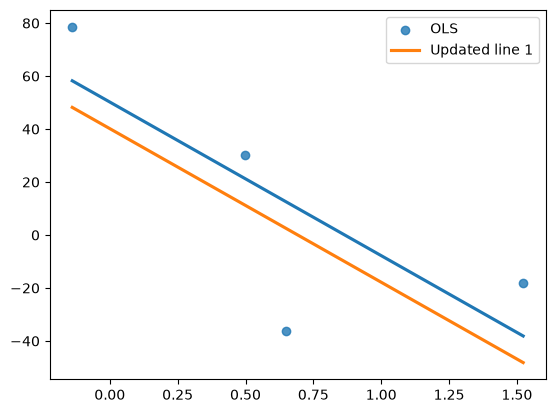

B:40.16252088753845


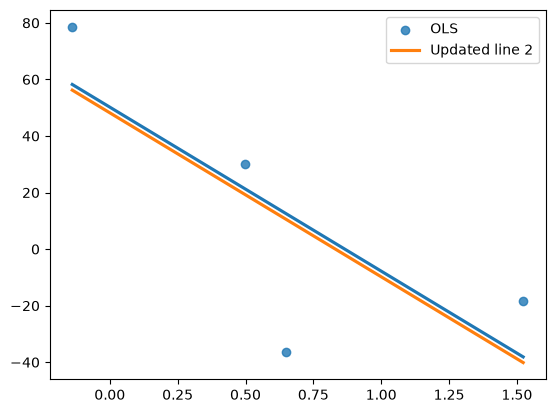

B:48.19502506504614


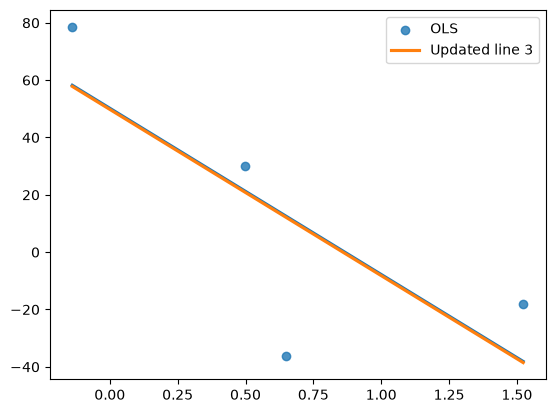

B:49.80152590054768


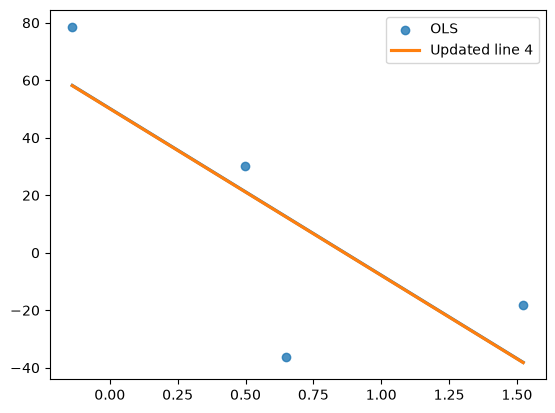

B:50.122826067647985


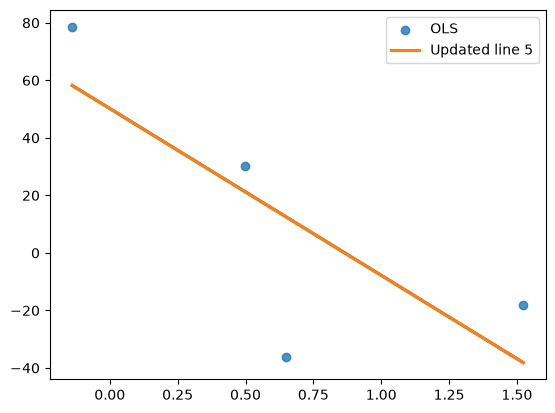

B:50.18708610106805


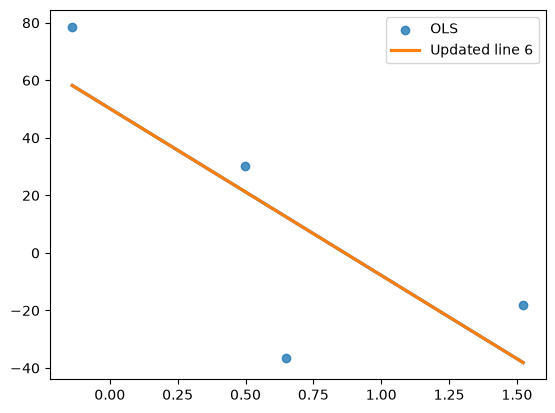

B:50.19993810775206


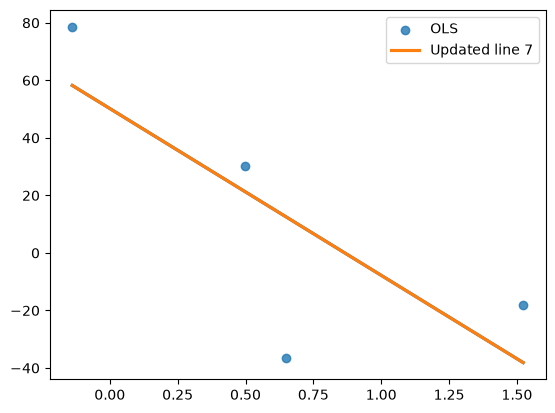

B:50.202508509088865


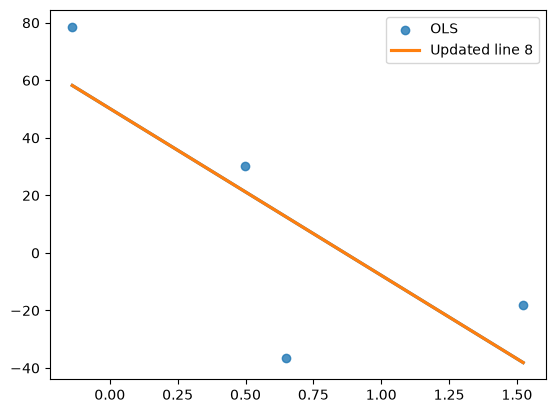

B:50.20302258935622


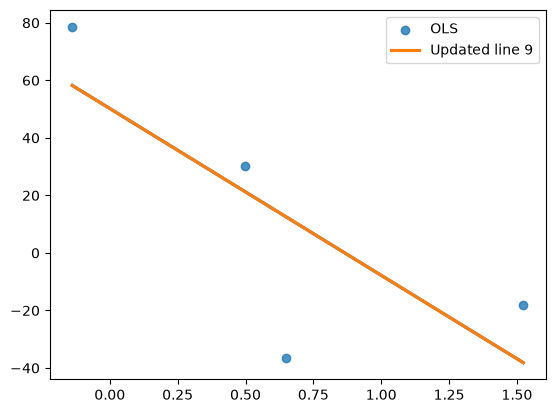

B:50.20312540540969


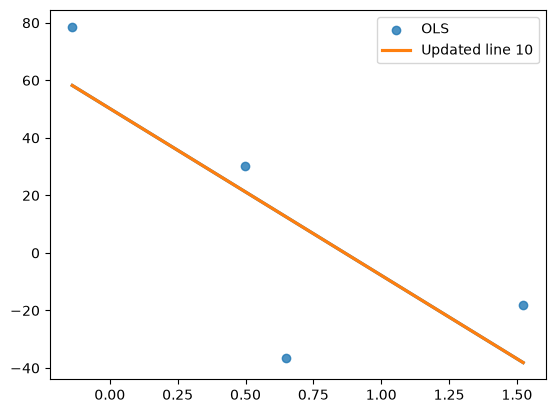

B:50.20314596862039


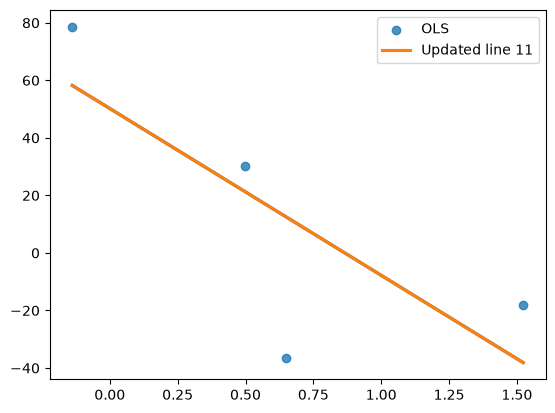

B:50.20315008126253


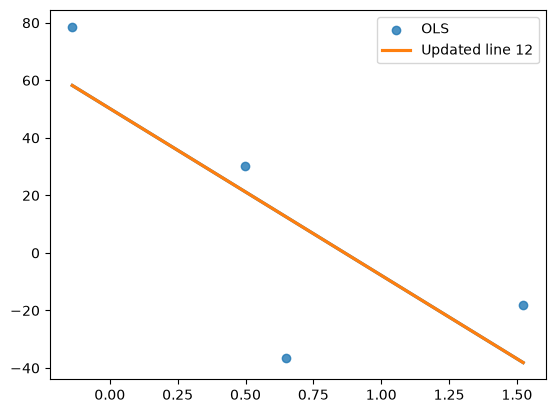

B:50.203150903790956


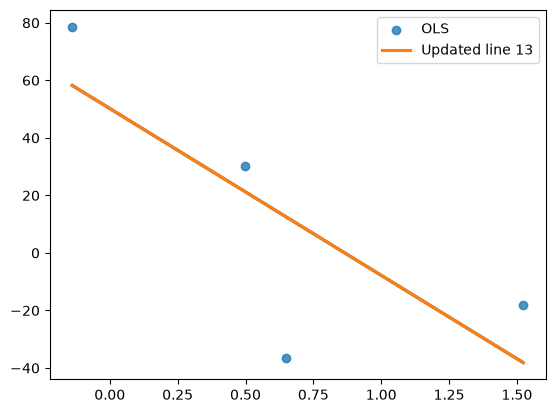

B:50.20315106829664


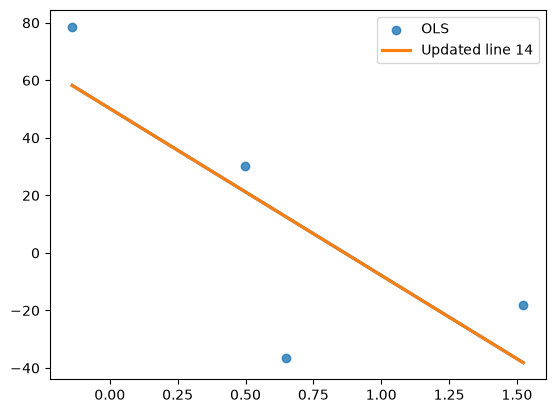

B:50.20315110119778


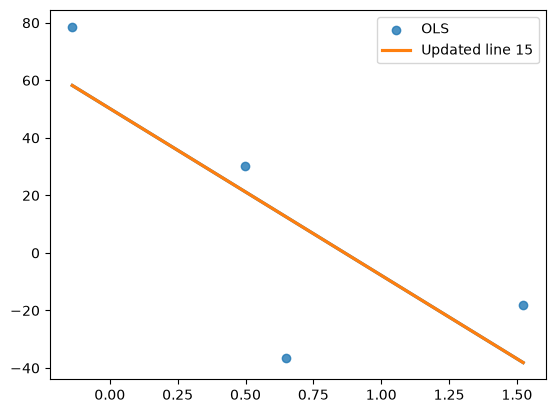

B:50.203151107778005


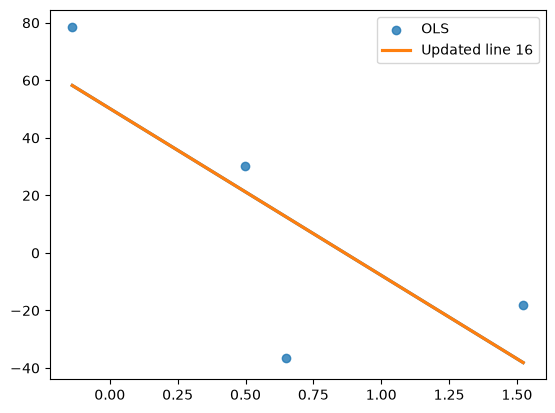

B:50.20315110909405


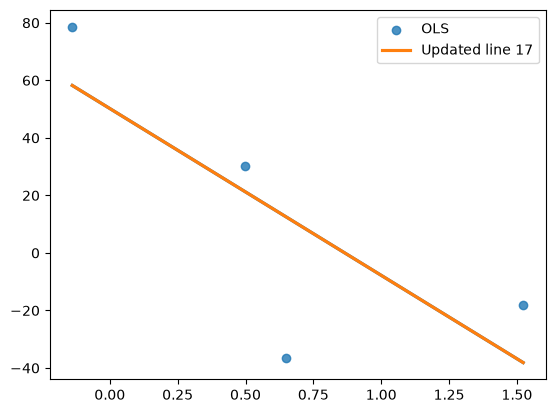

B:50.203151109357265


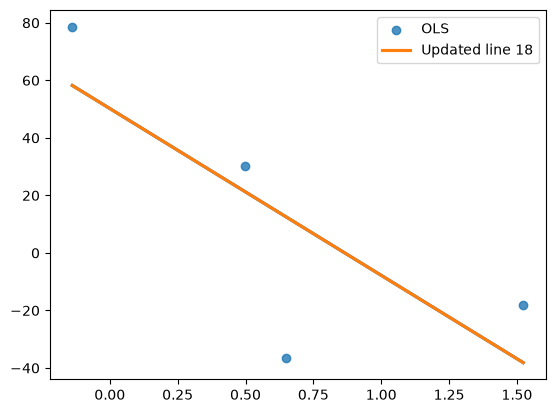

B:50.2031511094099


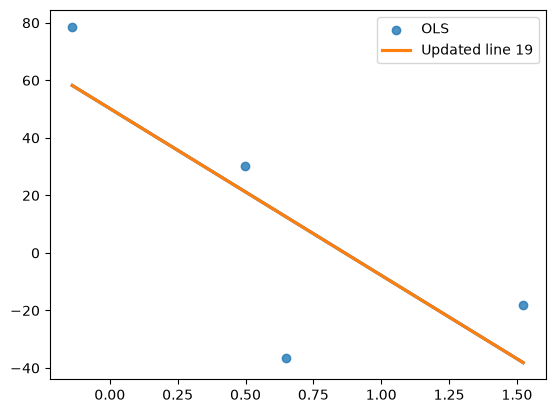

B:50.20315110942043


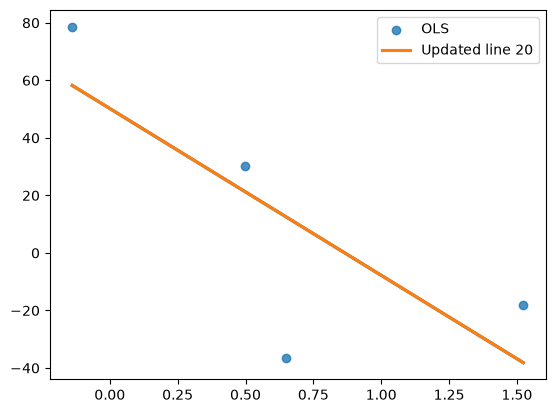

B:50.203151109422535
B:50.203151109422535 is now equal to OLS B:50.20315110942306


In [166]:
epochs = 20
b = 0
n = 0.1

for i in range(1,epochs+1):
    loss_slope = -2*np.sum(y - lr.coef_*X.ravel() - b)
    step_size = loss_slope*n
    b = b - step_size
    sns.regplot(x=X,y=y,ci=None,label='OLS')
    sns.regplot(x=X,y=((lr.coef_ * X) + b).reshape(4),ci=None,scatter=False,label = f'Updated line {i}')
    plt.legend()
    plt.show()
    print(f"B:{b}")
print(f"B:{b} is now equal to OLS B:{lr.intercept_}")

## Stopping Condition
#### 1- When there is no significant change in the new and old value of B
#### 2- We can fix the no. of epochs